# Exploration of Data using WGMS Data

Glaciers inside rough Karakoram boundary: 16801
Total inventory glacier area (km²): 23656.44


,region,outline_id,latitude,longitude,area_km2
100548,ASW,RGI60-14.07524,35.4284,76.893900,1077.958
99817,ASW,RGI60-14.06794,35.7416,76.404700,809.109
93028,ASW,RGI60-14.00005,36.0064,75.593200,559.807
97500,ASW,RGI60-14.04477,36.0550,75.281000,495.645
98913,ASW,RGI60-14.05890,35.2958,77.428400,439.616
...,...,...,...,...,...
185682,ASC,RGI60-13.39663,35.7820,78.443000,0.017
186052,ASC,RGI60-13.40033,36.1017,78.262299,0.017
186293,ASC,RGI60-13.40274,36.6670,77.774000,0.017
186181,ASC,RGI60-13.40162,36.4540,77.878000,0.014


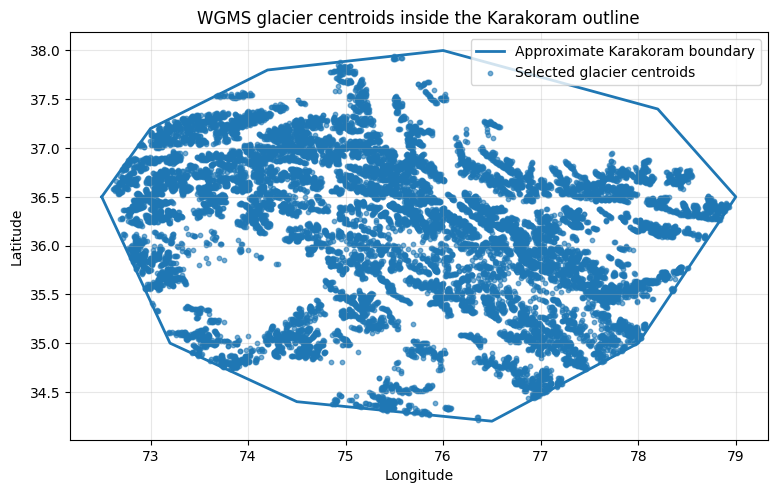

,area_weighted_mwe,mean_mwe,glaciers_with_data,area_with_data
year,,,,
1957,0.368619,0.394726,16801,23772.593
1958,0.848550,0.874724,16801,23772.593
1959,0.355815,0.380858,16801,23772.593
1960,0.417111,0.443371,16801,23772.593
1961,0.224388,0.249523,16801,23772.593
...,...,...,...,...
2021,-0.189361,-0.172486,16801,23772.593
2022,-0.778855,-0.748793,16801,23772.593
2023,-0.293474,-0.271400,16801,23772.593


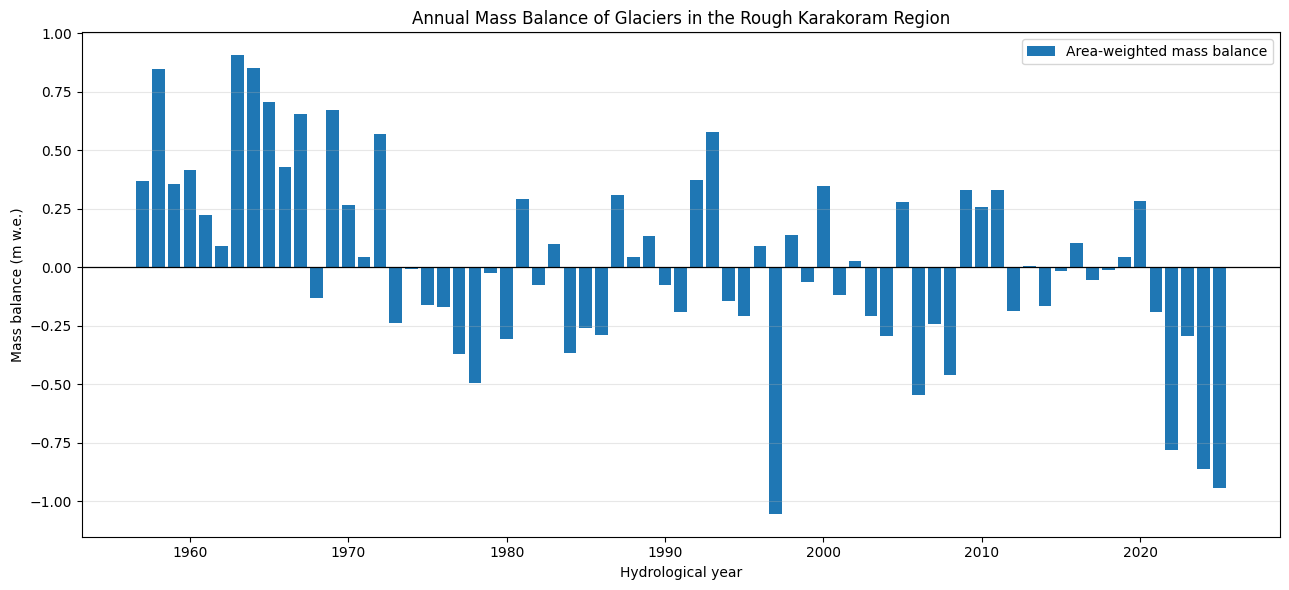

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import Point, Polygon

folder = Path("wgms-amce-2026-02-10/glacier")

# 1. Rough Karakoram outline: (longitude, latitude)
# Approximate research boundary, not an official range boundary
karakoram_coords = [
    (72.5, 36.5),
    (73.0, 37.2),
    (74.2, 37.8),
    (76.0, 38.0),
    (78.2, 37.4),
    (79.0, 36.5),
    (78.0, 35.0),
    (76.5, 34.2),
    (74.5, 34.4),
    (73.2, 35.0),
    (72.5, 36.5)
]
karakoram = Polygon(karakoram_coords)

# 2. Read all regional glacier metadata
metadata_parts = []

for file in folder.glob("*_metadata.csv"):
    region = file.stem.replace("_metadata", "")
    df = pd.read_csv(file)

    required = {"outline_id", "latitude", "longitude", "area_km2"}
    if not required.issubset(df.columns):
        continue

    for col in ["latitude", "longitude", "area_km2"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["region"] = region
    metadata_parts.append(df)

metadata = pd.concat(metadata_parts, ignore_index=True)
metadata = metadata.dropna(
    subset=["latitude", "longitude", "area_km2"]
)

# 3. Select glacier centroids inside the polygon
inside = metadata.apply(
    lambda r: karakoram.covers(
        Point(r["longitude"], r["latitude"])
    ),
    axis=1
)

glaciers = metadata.loc[inside].copy()
glaciers = glaciers.drop_duplicates(
    subset=["region", "outline_id"]
)

print("Glaciers inside rough Karakoram boundary:", len(glaciers))
print("Total inventory glacier area (km²):",
      round(glaciers["area_km2"].sum(), 2))

display(
    glaciers.sort_values("area_km2", ascending=False)[
        ["region", "outline_id", "latitude",
         "longitude", "area_km2"]
    ]
)

# 4. Plot the rough boundary and selected glacier centroids
fig, ax = plt.subplots(figsize=(9, 8))

x, y = karakoram.exterior.xy
ax.plot(x, y, linewidth=2, label="Approximate Karakoram boundary")
ax.scatter(
    glaciers["longitude"], glaciers["latitude"],
    s=10, alpha=0.6, label="Selected glacier centroids"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("WGMS glacier centroids inside the Karakoram outline")
ax.legend()
ax.grid(alpha=0.3)
ax.set_aspect("equal")
plt.show()

# 5. Load annual mass-change series for selected glaciers
mass_parts = []

for region, group in glaciers.groupby("region"):
    mass_file = folder / f"{region}_mwe.csv"

    if not mass_file.exists():
        print(f"Missing mass file: {mass_file.name}")
        continue

    mass = pd.read_csv(mass_file)
    year_cols = [c for c in mass.columns if str(c).isdigit()]

    if not year_cols:
        continue

    selected = group[["outline_id", "area_km2"]].merge(
        mass[["outline_id"] + year_cols],
        on="outline_id",
        how="inner"
    )

    if selected.empty:
        continue

    long = selected.melt(
        id_vars=["outline_id", "area_km2"],
        value_vars=year_cols,
        var_name="year",
        value_name="mass_change_mwe"
    )

    long["year"] = pd.to_numeric(long["year"])
    long["mass_change_mwe"] = pd.to_numeric(
        long["mass_change_mwe"], errors="coerce"
    )

    mass_parts.append(long)

if not mass_parts:
    raise ValueError(
        "No matching annual mass-change records found. "
        "Check the folder path and regional CSV files."
    )

data = pd.concat(mass_parts, ignore_index=True)
data = data.dropna(subset=["mass_change_mwe", "area_km2"])
data = data[data["area_km2"] > 0]

# 6. Calculate annual regional mass balance
# Area-weighted average in metres water equivalent
data["weighted_change"] = (
    data["mass_change_mwe"] * data["area_km2"]
)

annual = data.groupby("year").agg(
    weighted_sum=("weighted_change", "sum"),
    area_with_data=("area_km2", "sum"),
    glaciers_with_data=("outline_id", "nunique"),
    mean_mwe=("mass_change_mwe", "mean")
)

annual["area_weighted_mwe"] = (
    annual["weighted_sum"] / annual["area_with_data"]
)

annual.index = annual.index.astype(int)
annual.index.name = "year"

display(annual[[
    "area_weighted_mwe",
    "mean_mwe",
    "glaciers_with_data",
    "area_with_data"
]])

# 7. Plot annual regional mass balance
fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    annual.index,
    annual["area_weighted_mwe"],
    label="Area-weighted mass balance"
)

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlabel("Hydrological year")
ax.set_ylabel("Mass balance (m w.e.)")
ax.set_title("Annual Mass Balance of Glaciers in the Rough Karakoram Region")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

karakoram_annual = annual.copy()

Glaciers inside Swiss Alps: 2076
Total inventory glacier area (km²): 1279.42


,region,outline_id,latitude,longitude,area_km2
32513,CEU,RGI60-11.01450,46.5028,8.01919,82.206
33887,CEU,RGI60-11.02822,45.9502,7.80309,56.464
32541,CEU,RGI60-11.01478,46.5169,8.12141,31.334
34710,CEU,RGI60-11.03643,45.8830,6.93400,24.179
32391,CEU,RGI60-11.01328,46.5642,8.21930,23.825
...,...,...,...,...,...
34556,CEU,RGI60-11.03490,46.0200,6.84500,0.010
32862,CEU,RGI60-11.01799,46.4764,7.95503,0.010
33038,CEU,RGI60-11.01975,46.4154,7.58267,0.010
34925,CEU,RGI60-11.03856,46.0670,9.94500,0.010


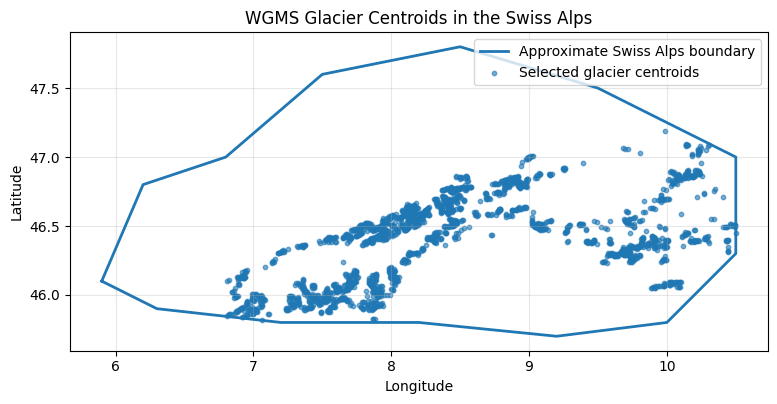

,area_weighted_mwe,mean_mwe,glaciers_with_data,area_with_data
year,,,,
1915,0.833693,1.004664,2076,1279.631
1916,0.982452,1.153583,2076,1279.631
1917,-0.115754,0.055376,2076,1279.631
1918,0.625993,0.797280,2076,1279.631
1919,0.365445,0.523442,2076,1279.631
...,...,...,...,...
2021,-0.520860,-0.317153,2076,1279.631
2022,-3.213263,-3.060091,2076,1279.631
2023,-2.180007,-2.029042,2076,1279.631


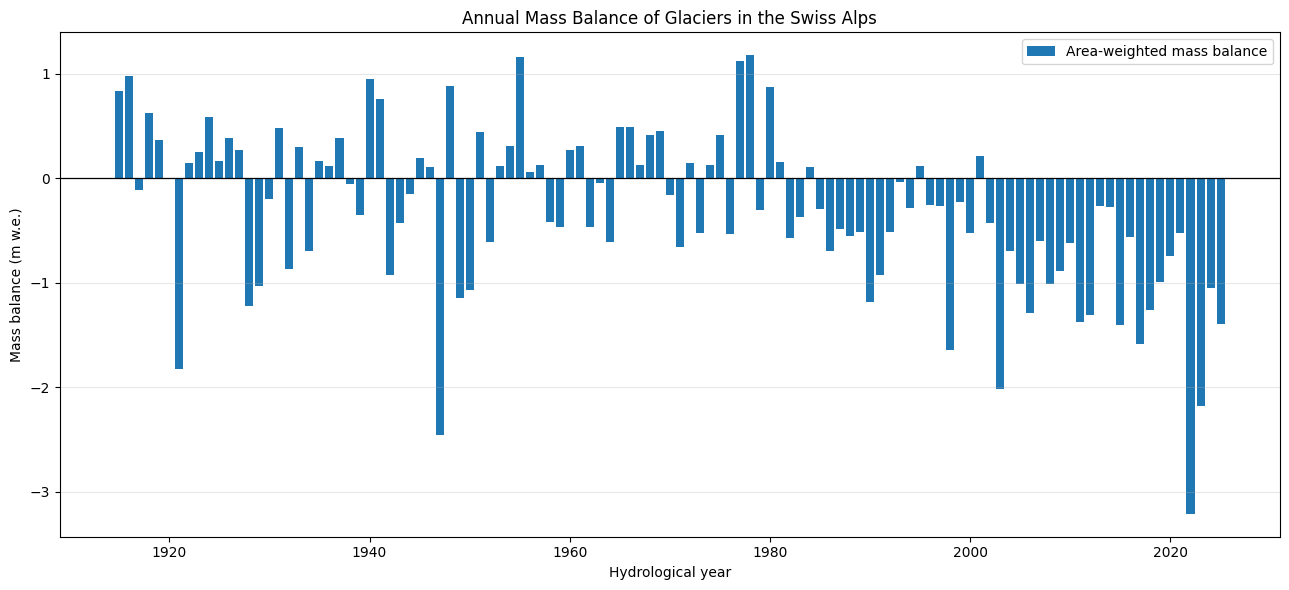

In [2]:

folder = Path("wgms-amce-2026-02-10/glacier")

# 1. Rough Swiss Alps boundary (longitude, latitude)
swiss_alps_coords = [
    (5.9, 46.1),
    (6.2, 46.8),
    (6.8, 47.0),
    (7.5, 47.6),
    (8.5, 47.8),
    (9.5, 47.5),
    (10.5, 47.0),
    (10.5, 46.3),
    (10.0, 45.8),
    (9.2, 45.7),
    (8.2, 45.8),
    (7.2, 45.8),
    (6.3, 45.9),
    (5.9, 46.1)
]

swiss_alps = Polygon(swiss_alps_coords)

# 2. Read all regional glacier metadata
metadata_parts = []

for file in folder.glob("*_metadata.csv"):
    region = file.stem.replace("_metadata", "")
    df = pd.read_csv(file)

    required = {"outline_id", "latitude", "longitude", "area_km2"}
    if not required.issubset(df.columns):
        continue

    for col in ["latitude", "longitude", "area_km2"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["region"] = region
    metadata_parts.append(df)

metadata = pd.concat(metadata_parts, ignore_index=True)
metadata = metadata.dropna(
    subset=["latitude", "longitude", "area_km2"]
)

# 3. Select glaciers inside polygon
inside = metadata.apply(
    lambda r: swiss_alps.covers(
        Point(r["longitude"], r["latitude"])
    ),
    axis=1
)

glaciers = metadata.loc[inside].copy()
glaciers = glaciers.drop_duplicates(
    subset=["region", "outline_id"]
)

print("Glaciers inside Swiss Alps:", len(glaciers))
print("Total inventory glacier area (km²):",
      round(glaciers["area_km2"].sum(), 2))

display(
    glaciers.sort_values("area_km2", ascending=False)[
        ["region", "outline_id", "latitude",
         "longitude", "area_km2"]
    ]
)

# 4. Plot boundary and selected glaciers
fig, ax = plt.subplots(figsize=(9, 8))

x, y = swiss_alps.exterior.xy
ax.plot(x, y, linewidth=2, label="Approximate Swiss Alps boundary")

ax.scatter(
    glaciers["longitude"], glaciers["latitude"],
    s=10, alpha=0.6, label="Selected glacier centroids"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("WGMS Glacier Centroids in the Swiss Alps")
ax.legend()
ax.grid(alpha=0.3)
ax.set_aspect("equal")
plt.show()

# 5. Load annual mass-change data
mass_parts = []

for region, group in glaciers.groupby("region"):
    mass_file = folder / f"{region}_mwe.csv"

    if not mass_file.exists():
        print(f"Missing mass file: {mass_file.name}")
        continue

    mass = pd.read_csv(mass_file)
    year_cols = [c for c in mass.columns if str(c).isdigit()]

    if not year_cols:
        continue

    selected = group[["outline_id", "area_km2"]].merge(
        mass[["outline_id"] + year_cols],
        on="outline_id",
        how="inner"
    )

    if selected.empty:
        continue

    long = selected.melt(
        id_vars=["outline_id", "area_km2"],
        value_vars=year_cols,
        var_name="year",
        value_name="mass_change_mwe"
    )

    long["year"] = pd.to_numeric(long["year"])
    long["mass_change_mwe"] = pd.to_numeric(
        long["mass_change_mwe"], errors="coerce"
    )

    mass_parts.append(long)

if not mass_parts:
    raise ValueError("No matching annual mass-change records found.")

data = pd.concat(mass_parts, ignore_index=True)
data = data.dropna(subset=["mass_change_mwe", "area_km2"])
data = data[data["area_km2"] > 0]

# 6. Calculate area-weighted annual mass balance
data["weighted_change"] = (
    data["mass_change_mwe"] * data["area_km2"]
)

annual = data.groupby("year").agg(
    weighted_sum=("weighted_change", "sum"),
    area_with_data=("area_km2", "sum"),
    glaciers_with_data=("outline_id", "nunique"),
    mean_mwe=("mass_change_mwe", "mean")
)

annual["area_weighted_mwe"] = (
    annual["weighted_sum"] / annual["area_with_data"]
)

annual.index = annual.index.astype(int)
annual.index.name = "year"

display(annual[[
    "area_weighted_mwe",
    "mean_mwe",
    "glaciers_with_data",
    "area_with_data"
]])

# 7. Plot annual regional mass balance
fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    annual.index,
    annual["area_weighted_mwe"],
    label="Area-weighted mass balance"
)

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlabel("Hydrological year")
ax.set_ylabel("Mass balance (m w.e.)")
ax.set_title("Annual Mass Balance of Glaciers in the Swiss Alps")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

swiss_alps_annual = annual.copy()

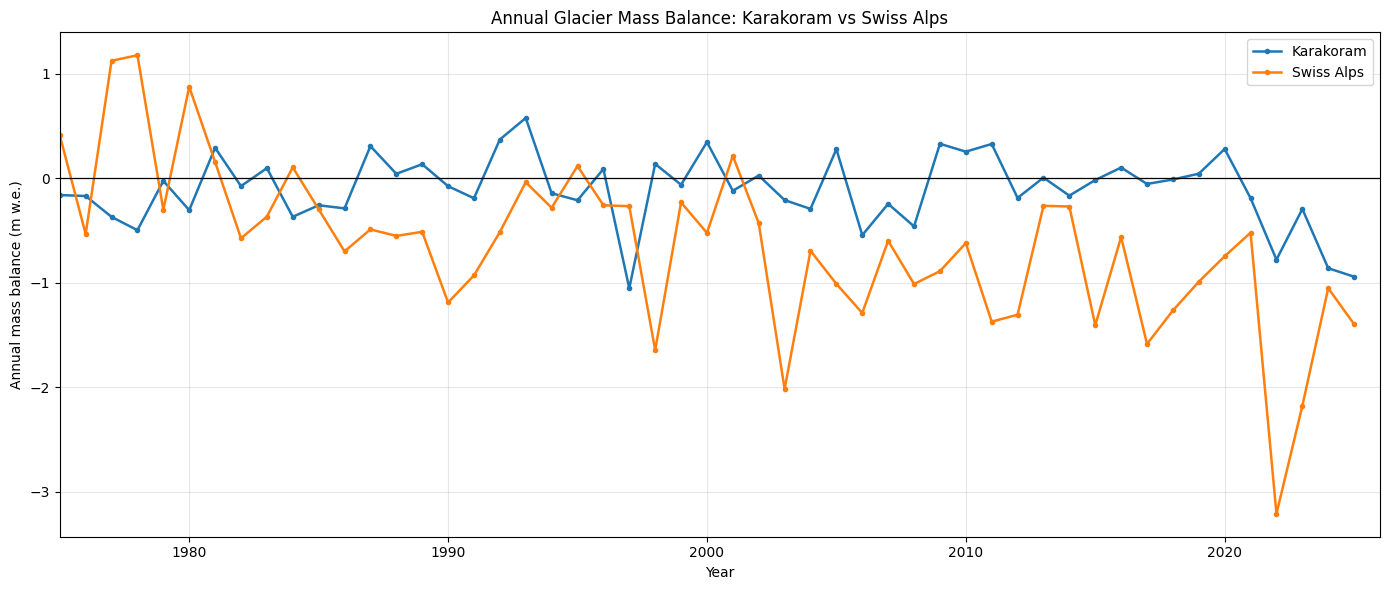

In [3]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    karakoram_annual.index,
    karakoram_annual["area_weighted_mwe"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Karakoram"
)

ax.plot(
    swiss_alps_annual.index,
    swiss_alps_annual["area_weighted_mwe"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Swiss Alps"
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xlim(1975, 2026)
ax.set_xlabel("Year")
ax.set_ylabel("Annual mass balance (m w.e.)")
ax.set_title("Annual Glacier Mass Balance: Karakoram vs Swiss Alps")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### this is not as useful because we can't see the cumulative effect, lets try doing that

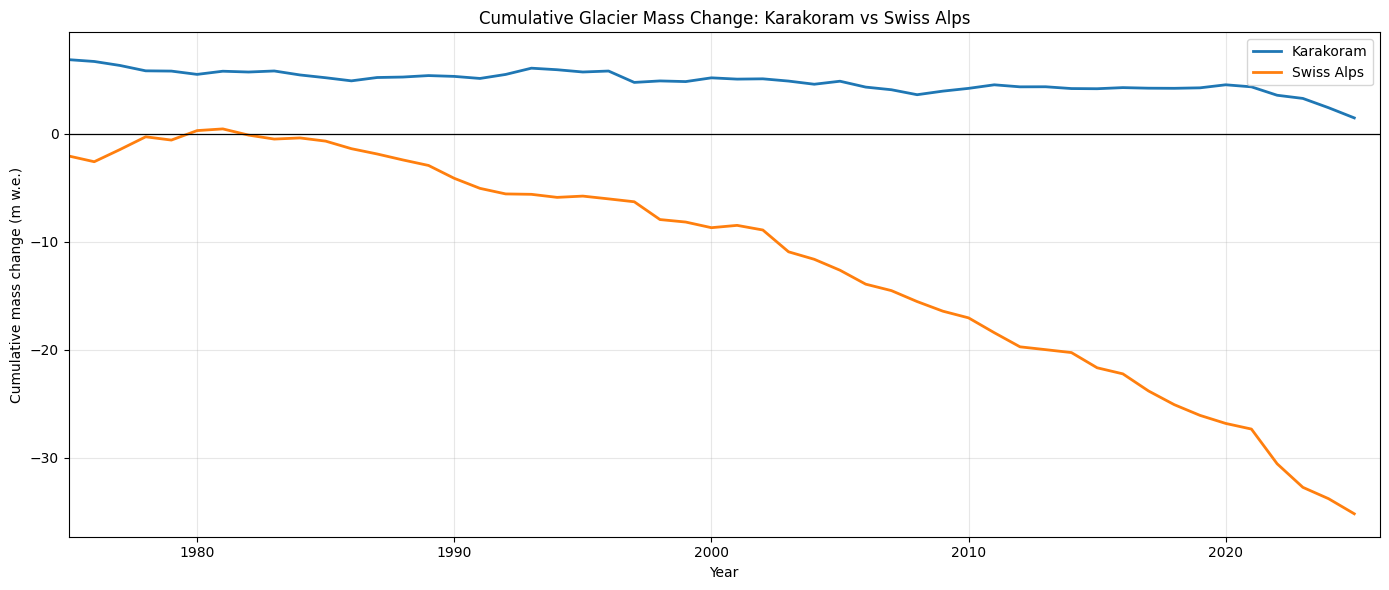

In [6]:
karakoram_cumulative = karakoram_annual["area_weighted_mwe"].cumsum()
swiss_alps_cumulative = swiss_alps_annual["area_weighted_mwe"].cumsum()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    karakoram_cumulative.index,
    karakoram_cumulative.values,
    linewidth=2,
    label="Karakoram"
)

ax.plot(
    swiss_alps_cumulative.index,
    swiss_alps_cumulative.values,
    linewidth=2,
    label="Swiss Alps"
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xlim(1975, 2026)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title("Cumulative Glacier Mass Change: Karakoram vs Swiss Alps")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### We can clearly see that the data is showing a trend but we need to just adjust the data so they start at the same starting point

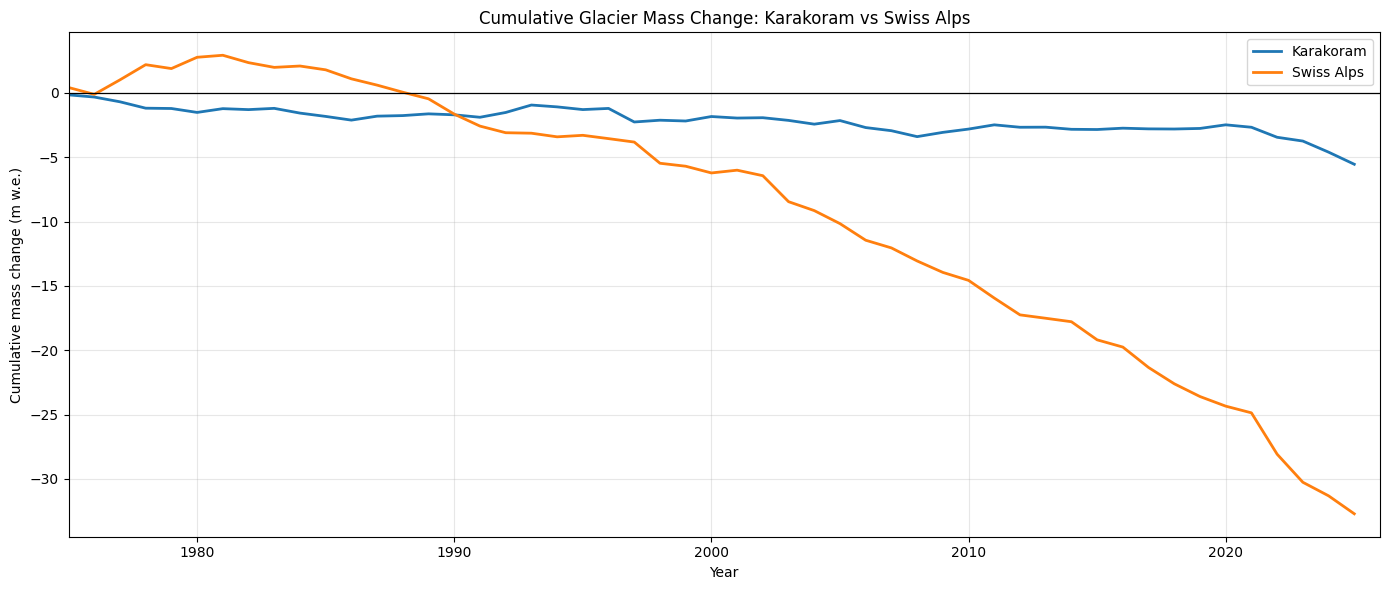

In [7]:
start = 1975

k = karakoram_annual.loc[start:, "area_weighted_mwe"]
s = swiss_alps_annual.loc[start:, "area_weighted_mwe"]

karakoram_cumulative = k.cumsum()
swiss_alps_cumulative = s.cumsum()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    karakoram_cumulative.index,
    karakoram_cumulative.values,
    linewidth=2,
    label="Karakoram"
)

ax.plot(
    swiss_alps_cumulative.index,
    swiss_alps_cumulative.values,
    linewidth=2,
    label="Swiss Alps"
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xlim(1975, 2026)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title("Cumulative Glacier Mass Change: Karakoram vs Swiss Alps")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Even though these are absolute values these work because: It’s mass per unit area, so a small glacier and a large one can be compared directly. A 1 km² glacier at −1 m w.e. lost 1 million m³ of water equivalent (1 million tonnes). A 100 km² glacier at −1 m w.e. lost 100 million tonnes.

---

### I created a function to calculate the regional mass balance for any given polygon coordinates. This function takes a list of (longitude, latitude) tuples defining the polygon and a name for the region. It returns the selected glaciers and their annual mass balance data.

Glaciers inside Andes boundary: 5823
Total inventory glacier area (km²): 3892.69


,region,outline_id,latitude,longitude,area_km2
67627,SA2,RGI60-17.01218,-34.60720,-70.3361,110.978
71795,SA2,RGI60-17.13796,-33.49150,-69.7567,69.313
71798,SA2,RGI60-17.13799,-33.38160,-69.7313,29.768
72017,SA2,RGI60-17.14015,-33.09350,-70.1163,24.719
71703,SA2,RGI60-17.13704,-33.71190,-69.9002,23.266
...,...,...,...,...,...
145180,TRP,RGI60-16.02113,-13.04810,-75.0568,0.010
145181,TRP,RGI60-16.02114,-9.52674,-77.3811,0.010
70712,SA2,RGI60-17.12716,-38.69680,-71.7858,0.010
70589,SA2,RGI60-17.12593,-38.98120,-71.5519,0.010


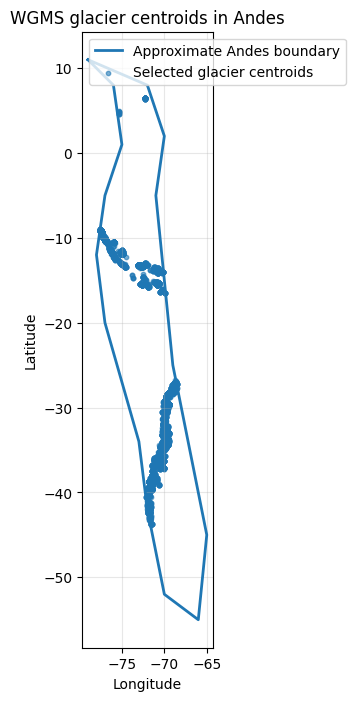

,area_weighted_mwe,mean_mwe,glaciers_with_data,area_with_data
year,,,,
1976,-0.485554,-0.385778,5823,4003.885
1977,-0.650884,-0.550772,5823,4003.885
1978,-0.006428,0.092224,5823,4003.885
1979,0.207099,0.305211,5823,4003.885
1980,0.046111,0.144568,5823,4003.885
1981,0.072379,0.170740,5823,4003.885
1982,-1.137934,-1.036936,5823,4003.885
1983,1.526816,1.621890,5823,4003.885
1984,-0.623784,-0.523995,5823,4003.885


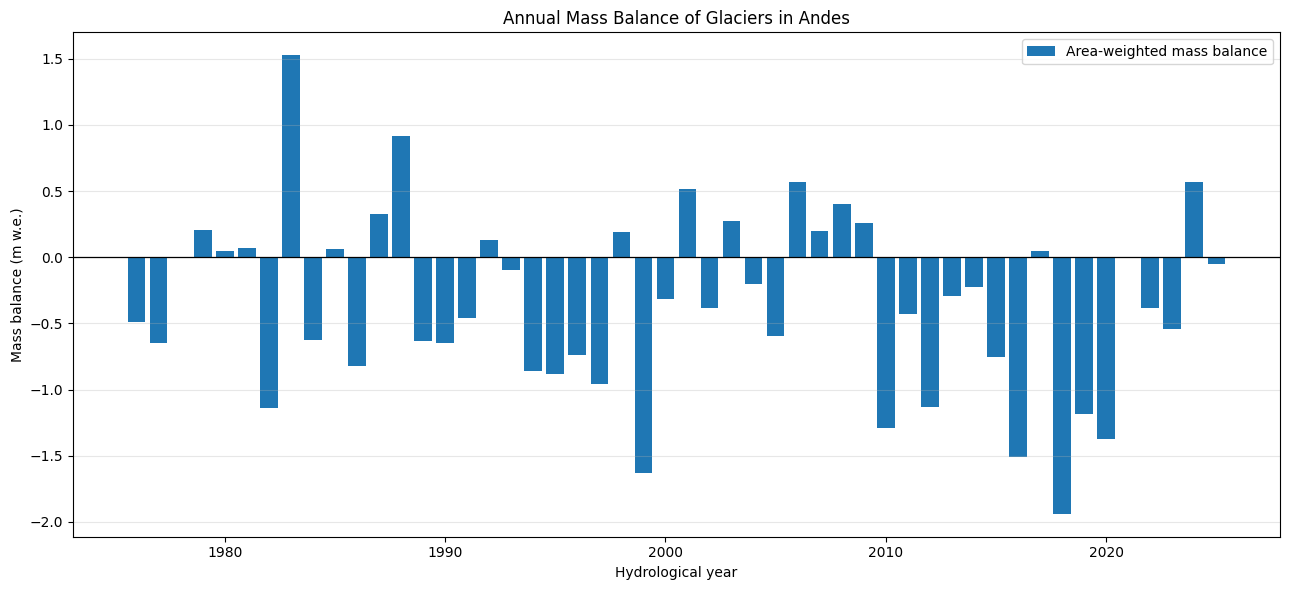

In [13]:
from wgms_exploration import regional_mass_balance

andes_coords = [
    (-79.0, 11.0),
    (-76.0, 8.0),
    (-75.0, 1.0),
    (-77.0, -5.0),
    (-78.0, -12.0),
    (-77.0, -20.0),
    (-75.0, -27.0),
    (-73.0, -34.0),
    (-72.0, -42.0),
    (-70.0, -52.0),
    (-66.0, -55.0),
    (-65.0, -45.0),
    (-67.0, -35.0),
    (-69.0, -25.0),
    (-70.0, -15.0),
    (-71.0, -5.0),
    (-70.0, 2.0),
    (-72.0, 8.0),
    (-79.0, 11.0)
]

glaciers_p, andes_annual = regional_mass_balance(andes_coords, "Andes")




In [17]:
kunlun_coords = [
    (77.0, 36.0),
    (78.0, 36.8),
    (80.0, 37.5),
    (82.0, 37.8),
    (84.0, 37.5),
    (86.0, 37.0),
    (88.0, 36.5),
    (90.0, 36.0),
    (92.0, 35.5),
    (94.0, 35.0),
    (96.0, 34.5),
    (98.0, 34.0),
    (99.0, 33.0),
    (97.0, 32.5),
    (94.0, 33.0),
    (91.0, 33.5),
    (88.0, 34.0),
    (85.0, 34.5),
    (82.0, 35.0),
    (79.0, 35.5),
    (77.0, 36.0)
]

kunlun_glaciers, kunlun_annual = regional_mass_balance(kunlun_coords, "Kunlun",verbose=False,plot=False)

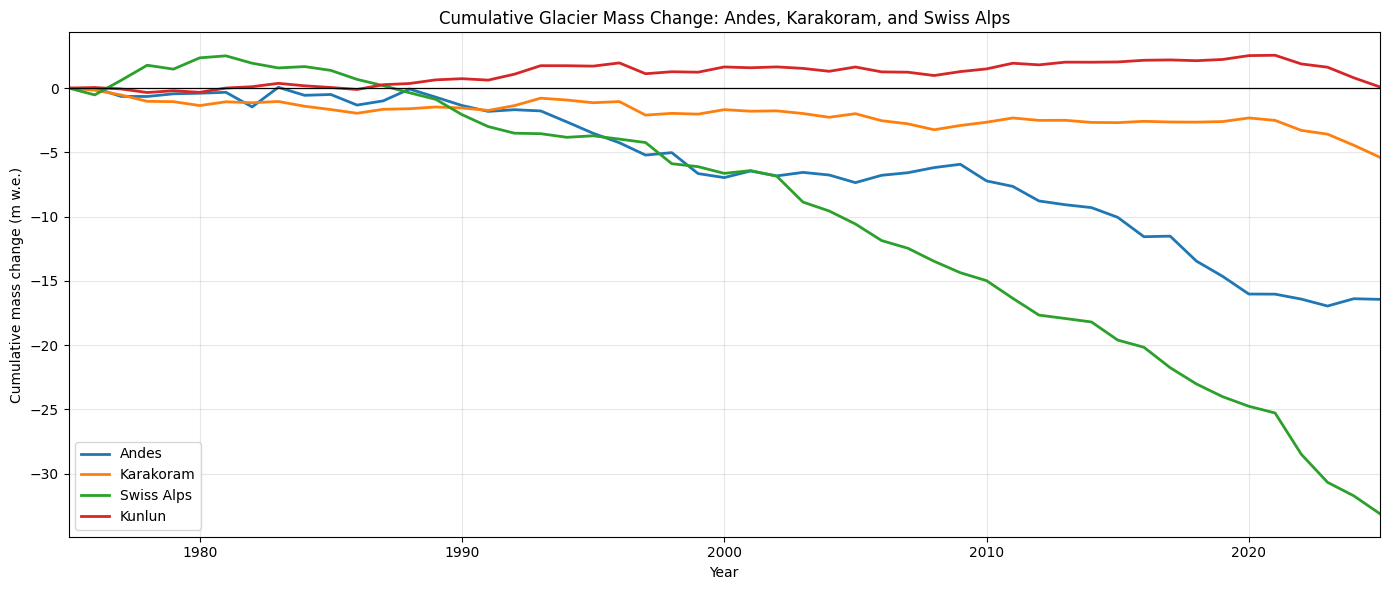

In [18]:
start = 1975

regional_annual = {
    "Andes": andes_annual,
    "Karakoram": karakoram_annual,
    "Swiss Alps": swiss_alps_annual,
    "Kunlun": kunlun_annual
}

fig, ax = plt.subplots(figsize=(14, 6))

for name, annual_data in regional_annual.items():
    series = annual_data.loc[
        start:, "area_weighted_mwe"
    ].dropna()

    cumulative = series.cumsum()
    cumulative = cumulative - cumulative.iloc[0]

    ax.plot(
        cumulative.index,
        cumulative.values,
        linewidth=2,
        label=name
    )

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlim(start, 2025)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title(
    "Cumulative Glacier Mass Change: Andes, Karakoram, and Swiss Alps"
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
REGIONS = {
    # Near the Karakoram (the anomaly question)
    "Pamir":             [(70.5, 36.5),(72.0, 36.0),(73.5, 36.5),(75.5, 37.0),(76.5, 38.0),(75.5, 39.5),(73.5, 40.0),(71.5, 39.5),(70.5, 38.5),(70.5, 36.5)],
    "Hindu Kush":       [(69, 34.5), (73, 34.5), (73, 37), (69, 37)],
    "Tien Shan":        [(69, 40), (82, 40), (82, 44), (69, 44)],
    "Central Himalaya": [(80, 27), (89, 27), (89, 30), (80, 30)],
    "Eastern Himalaya": [(89, 27), (97, 27), (97, 30), (89, 30)],

    # Global comparison regions
    "Scandinavia":      [(5, 59.5), (9, 59.5), (9, 70), (5, 70)],
    "Svalbard":         [(10, 76.5), (35, 76.5), (35, 80.5), (10, 80.5)],
    "Caucasus":         [(37, 41), (49, 41), (49, 44), (37, 44)],
    "Alaska":           [(-153, 58), (-130, 58), (-130, 64), (-153, 64)],
    "Patagonia":        [(-75, -52), (-72, -52), (-72, -46), (-75, -46)],
    "New Zealand":      [(167, -46), (172, -46), (172, -43), (167, -43)],
}

meta = load_wgms_metadata()
results = {}
for name, coords in REGIONS.items():
    try:
        g, a = regional_mass_balance(coords, name, metadata=meta,
                                     plot=False, verbose=False)
        results[name] = a
        print(f"{name}: {len(g)} glaciers, {a.index.min()}-{a.index.max()}")
    except ValueError:
        print(f"{name}: no data")

Pamir: 14149 glaciers, 1957-2025
Hindu Kush: 4449 glaciers, 1957-2025
Tien Shan: 8862 glaciers, 1957-2025
Central Himalaya: 6291 glaciers, 1957-2025
Eastern Himalaya: 4966 glaciers, 1957-2025
Scandinavia: 1536 glaciers, 1946-2025
Svalbard: 1567 glaciers, 1946-2025
Caucasus: 2016 glaciers, 1953-2025
Alaska: 18036 glaciers, 1946-2025
Patagonia: 5821 glaciers, 1976-2025
New Zealand: 3403 glaciers, 1976-2025


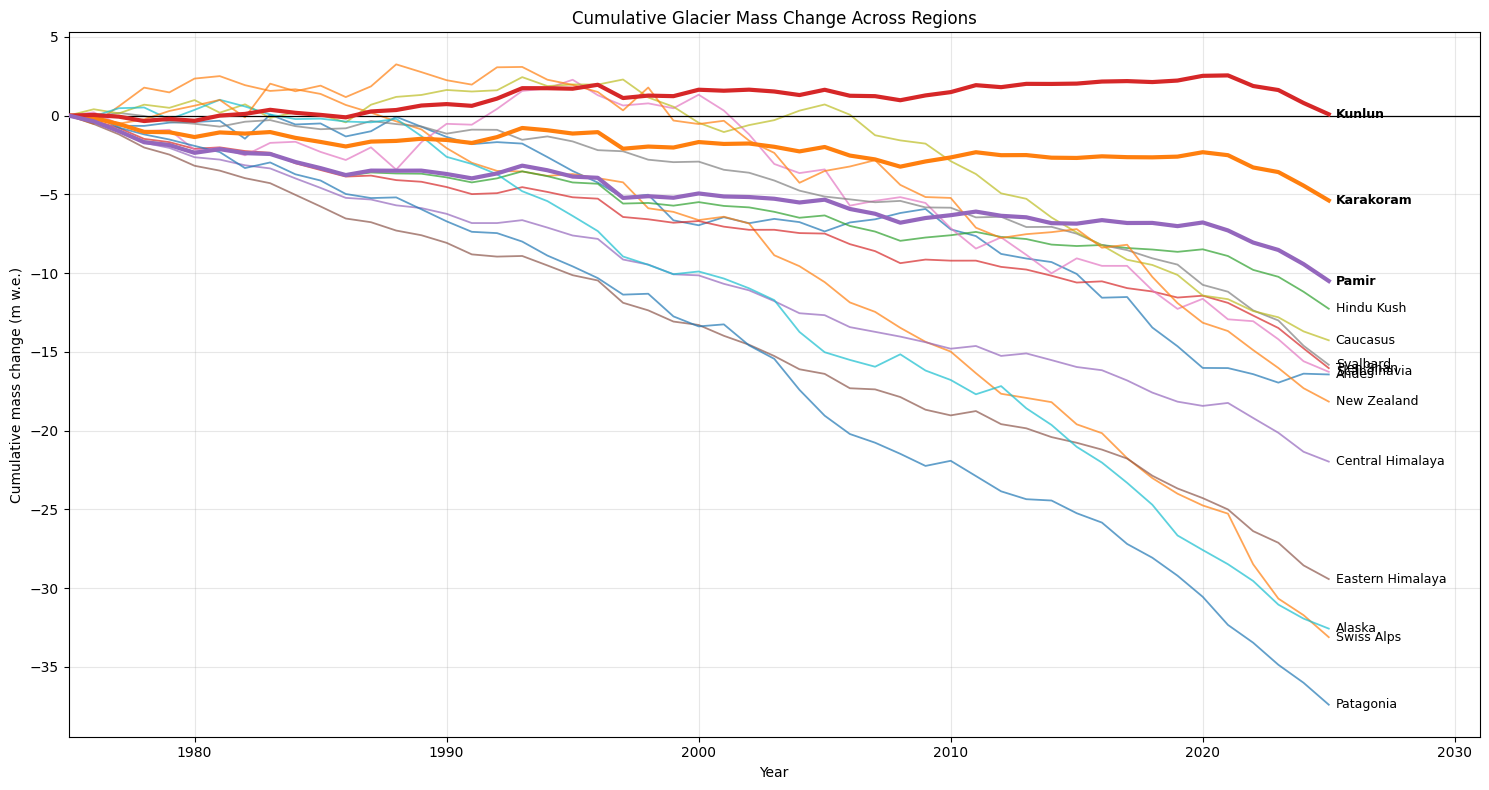

In [24]:
import matplotlib.pyplot as plt

all_regions = {
    "Andes": andes_annual,
    "Karakoram": karakoram_annual,
    "Kunlun": kunlun_annual,
    "Swiss Alps": swiss_alps_annual,
    **results,   # Pamir, Hindu Kush, Tien Shan, etc. from the REGIONS loop
}

start, end = 1975, 2025
highlight = {"Karakoram": "tab:orange", "Kunlun": "tab:red", "Pamir": "tab:purple"}
min_years = 10 

fig, ax = plt.subplots(figsize=(15, 8))

for name, annual in all_regions.items():
    series = annual.loc[start:end, "area_weighted_mwe"].dropna()
    if len(series) < min_years:
        print(f"Skipping {name}: only {len(series)} years of data")
        continue

    cum = series.cumsum()
    cum = cum - cum.iloc[0]          # every line starts at 0

    if name in highlight:
        ax.plot(cum.index, cum.values, linewidth=3, color=highlight[name], zorder=3)
    else:
        ax.plot(cum.index, cum.values, linewidth=1.3, alpha=0.7)

    ax.annotate(name, (cum.index[-1], cum.values[-1]),
                xytext=(5, 0), textcoords="offset points",
                fontsize=9, va="center",
                fontweight="bold" if name in highlight else "normal")

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlim(start, end + 6)          # extra room for the labels
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title("Cumulative Glacier Mass Change Across Regions")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:

from scipy import stats

def stability_summary(annual, start=2000, end=2025, tol=0.15):
    s = annual.loc[start:end, "area_weighted_mwe"].dropna()
    n = len(s)
    mean = s.mean()
    sem = s.std(ddof=1) / np.sqrt(n)
    lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
    t, p = stats.ttest_1samp(s, 0)
    slope = stats.linregress(s.index, s.values).slope
    return {
        "years": n,
        "mean_mwe_per_yr": round(mean, 3),
        "95%_CI": (round(lo, 3), round(hi, 3)),
        "p_vs_zero": round(p, 3),
        "within_tol": abs(mean) <= tol,
        "ci_includes_zero": lo <= 0 <= hi,
        "trend_per_yr": round(slope, 4),
    }

summary = pd.DataFrame({name: stability_summary(a) for name, a in all_regions.items()}).T
summary

,years,mean_mwe_per_yr,95%_CI,p_vs_zero,within_tol,ci_includes_zero,trend_per_yr
Andes,26,-0.376,"(-0.641, -0.112)",0.01,False,False,-0.0254
Karakoram,26,-0.129,"(-0.268, 0.01)",0.08,True,True,-0.019
Kunlun,26,-0.044,"(-0.171, 0.083)",0.501,True,True,-0.0185
Swiss Alps,26,-1.039,"(-1.309, -0.768)",0.0,False,False,-0.0374
Pamir,26,-0.203,"(-0.347, -0.059)",0.01,False,False,-0.0228
Hindu Kush,26,-0.252,"(-0.392, -0.112)",0.002,False,False,-0.0201
Tien Shan,26,-0.355,"(-0.507, -0.204)",0.0,False,False,-0.0273
Central Himalaya,26,-0.457,"(-0.593, -0.322)",0.0,False,False,-0.0128
Eastern Himalaya,26,-0.629,"(-0.773, -0.485)",0.0,False,False,-0.0213
Scandinavia,26,-0.644,"(-0.995, -0.292)",0.001,False,False,-0.0034


![Map](maps/map.png)